The purpose of this exploratory data analysis (EDA) is to examine NBA player statistics and identify patterns that can help distinguish different playing styles. Our project aims to develop statistical player archetypes that provide a more detailed understanding of player roles than traditional basketball positions.

Using data collected from Basketball Reference and the NBA API, we will explore player performance, shooting tendencies, offensive involvement, playmaking, and defensive contributions. We will examine distributions, relationships between statistical features, and differences between players to identify patterns that may help inform our later PCA and clustering models.

The goal of this analysis is to better understand the dataset, identify important features, and determine which statistics are most useful for distinguishing NBA player archetypes.

In [21]:

# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the regular season dataset
df = pd.read_csv("../../data/processed/reg-szn/player_data_merged.csv")

# Display the original dataset dimensions
print("Original Dataset Shape:", df.shape)

# Remove the League Average row
df = df[df["Player"] != "League Average"].copy() 

# Reset the index
df = df.reset_index(drop=True)

# Display cleaned dataset dimensions
print("Dataset Shape After Cleaning:", df.shape)

# Display the first five rows
display(df.head())



Original Dataset Shape: (583, 233)
Dataset Shape After Cleaning: (582, 233)


,adjusted-shooting_Rk,Player,adjusted-shooting_Age,adjusted-shooting_Team,adjusted-shooting_Pos,adjusted-shooting_G,adjusted-shooting_GS,adjusted-shooting_MP,adjusted-shooting_FG%,adjusted-shooting_2P%,...,totals_DRB,totals_TRB,totals_AST,totals_STL,totals_BLK,totals_TOV,totals_PF,totals_PTS,totals_Trp-Dbl,totals_Awards
0,125.0,Precious Achiuwa,26.0,SAC,C,73.0,57.0,1745.0,0.528,0.577,...,315.0,492.0,101.0,65.0,50.0,65.0,123.0,736.0,0.0,NaN
1,337.0,Steven Adams,32.0,HOU,C,32.0,11.0,730.0,0.504,0.504,...,131.0,276.0,48.0,22.0,20.0,35.0,55.0,187.0,0.0,NaN
2,29.0,Bam Adebayo,28.0,MIA,C,73.0,73.0,2365.0,0.442,0.509,...,583.0,732.0,232.0,86.0,49.0,120.0,122.0,1468.0,0.0,DPOY-11DEF2
3,284.0,Ochai Agbaji,25.0,2TM,SG,62.0,13.0,973.0,0.436,0.579,...,95.0,141.0,47.0,24.0,17.0,31.0,93.0,314.0,0.0,NaN
4,233.0,Santi Aldama,25.0,MEM,PF,43.0,11.0,1198.0,0.479,0.572,...,220.0,287.0,126.0,37.0,31.0,55.0,69.0,602.0,0.0,NaN


In [22]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


2. Dataset Overview

Before performing statistical analysis, it is important to understand the structure of the dataset. This section examines the number of observations, available features, data types, and general characteristics of the NBA player data.

In [23]:

# Number of rows and columns
print("Number of Players:", df.shape[0])
print("Number of Features:", df.shape[1])

# Number of unique players
print("Unique Players:", df["Player"].nunique())

# Examine column names and data types
df.info()

# Generate descriptive statistics
display(df.describe().T)


Number of Players: 582
Number of Features: 233
Unique Players: 582
<class 'pandas.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Columns: 233 entries, adjusted-shooting_Rk to totals_Awards
dtypes: float64(207), str(26)
memory usage: 1.0 MB


,count,mean,std,min,25%,50%,75%,max
adjusted-shooting_Rk,582.0,291.500000,168.153204,1.0,146.25,291.5,436.75,582.0
adjusted-shooting_Age,582.0,25.884880,4.199272,19.0,23.00,25.0,28.00,41.0
adjusted-shooting_G,582.0,45.792096,24.937300,1.0,23.00,51.0,67.75,82.0
adjusted-shooting_GS,582.0,21.134021,25.423489,0.0,1.00,8.0,41.00,82.0
adjusted-shooting_MP,582.0,1019.786942,771.979401,3.0,293.25,940.5,1610.00,2953.0
...,...,...,...,...,...,...,...,...
totals_BLK,582.0,20.458763,24.895393,0.0,4.00,11.0,28.00,197.0
totals_TOV,582.0,58.309278,54.955127,0.0,14.00,42.5,85.00,259.0
totals_PF,582.0,83.969072,61.869741,0.0,27.00,78.0,131.00,267.0
totals_PTS,582.0,488.651203,459.775808,0.0,107.00,363.5,759.00,2143.0


### Initial Dataset Findings

The dataset contains 582 unique NBA players and 233 total columns, including 207 numerical features and 26 categorical or text features. These features cover several aspects of basketball performance, including shooting efficiency, offensive involvement, playmaking, rebounding, defense, and overall player production. The large number of available statistics provides a strong foundation for identifying differences in player styles and roles. However, some features measure similar aspects of performance using different formats, such as total statistics and per-game averages. Therefore, additional data exploration and feature selection will be important before applying dimensionality reduction and clustering techniques.

## 3. Data Quality and Missing Values

Before analyzing player statistics, we need to check the dataset for missing values and potential data-quality issues. Missing information can affect statistical calculations and machine learning models, so understanding where it occurs will help determine how the data should be prepared.

In [25]:

# Calculate missing values for each column
missing_values = df.isnull().sum()

# Calculate missing percentages
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

# Only show columns with missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

display(missing_summary)


,Missing Values,Missing Percentage
per-36-minutes_Awards,528,90.721649
per-100-possessions_Awards,528,90.721649
adjusted-shooting_Awards,528,90.721649
advanced_Awards,528,90.721649
per-game_Awards,528,90.721649
totals_Awards,528,90.721649
shooting_Awards,528,90.721649
play-by-play_Awards,528,90.721649
shooting_16-3P.1,127,21.821306
shooting_10-16.1,66,11.340206


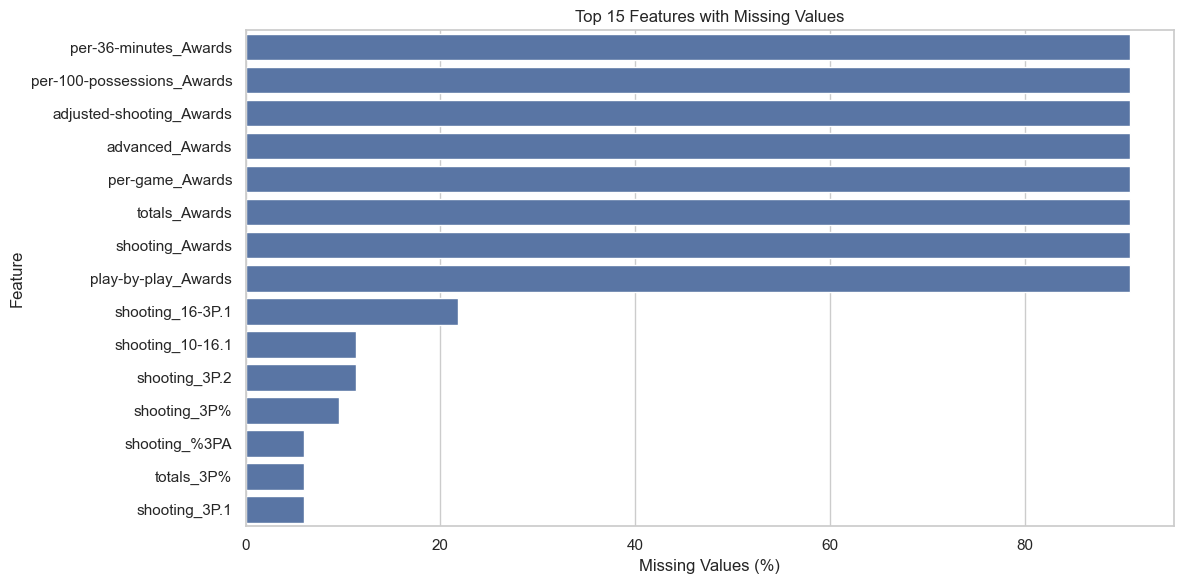

In [26]:

# Display the 15 columns with the most missing values
top_missing = missing_summary.head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_missing["Missing Percentage"],
    y=top_missing.index
)

plt.title("Top 15 Features with Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### Missing Value Findings

The missing value analysis shows that the majority of missing information is concentrated in award-related columns, with approximately 90% of observations missing in these features. This is expected because most NBA players do not receive awards during a season. Therefore, these columns are unlikely to be useful for our main analysis of player playing styles. Several shooting-related features also contain missing values, with some having between approximately 5% and 22% missing data. Since shooting tendencies are important for distinguishing player archetypes, these features should be investigated further before deciding whether to remove or handle their missing values. Overall, this analysis shows that missing values need to be considered carefully rather than automatically removing observations or columns.

In [27]:

# Exclude award-related columns
stat_columns = [
    col for col in df.columns
    if "Awards" not in col
]

# Calculate missing values for statistical features
stat_missing = df[stat_columns].isnull().sum()

# Calculate missing percentages
stat_missing_pct = (stat_missing / len(df)) * 100

# Create summary
stat_missing_summary = pd.DataFrame({
    "Missing Values": stat_missing,
    "Missing Percentage": stat_missing_pct
})

# Display only columns with missing values
stat_missing_summary = stat_missing_summary[
    stat_missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

display(stat_missing_summary.head(20))


,Missing Values,Missing Percentage
shooting_16-3P.1,127,21.821306
shooting_10-16.1,66,11.340206
shooting_3P.2,66,11.340206
shooting_3P%,56,9.621993
totals_3P%,35,6.013746
per-game_3P%,35,6.013746
shooting_%3PA,35,6.013746
shooting_3P.1,35,6.013746
adjusted-shooting_3P%,35,6.013746
per-36-minutes_3P%,35,6.013746


### Missing Values in Basketball Statistics

After excluding award-related columns, the missing value analysis shows that most basketball statistics have relatively complete data. The largest amount of missing information appears in shooting-related features, particularly certain field-goal distance categories. The feature `shooting_16-3P.1` has the highest percentage of missing values at approximately 21.82%, while several three-point percentage features have approximately 6.01% missing data. Some related shooting features also have identical missing-value counts, suggesting that missing information may affect multiple statistics for the same players. These findings indicate that shooting features should be examined carefully before deciding how to handle missing values, while most other player statistics appear suitable for further analysis.

## 4. Descriptive Statistics and Player Distributions

This section examines the distributions of important NBA player statistics to better understand differences in scoring, playmaking, rebounding, offensive involvement, and shooting efficiency. By looking at averages, medians, ranges, and standard deviations, we can identify how much variation exists between players and which statistics may be useful for distinguishing different playing styles.


In [28]:

# Select important basketball statistics
features = [
    "per-game_PTS",
    "per-game_AST",
    "per-game_TRB",
    "advanced_USG%",
    "advanced_TS%"
]

# Check that all selected columns exist
for col in features:
    if col not in df.columns:
        print("Missing column:", col)

# Display descriptive statistics
display(df[features].describe().T)


,count,mean,std,min,25%,50%,75%,max
per-game_PTS,582.0,9.157732,6.378730,0.0,4.300,7.8000,12.500,33.500
per-game_AST,582.0,2.142612,1.787056,0.0,0.900,1.6000,2.900,10.700
per-game_TRB,582.0,3.581787,2.348760,0.0,1.900,3.1000,4.900,12.900
advanced_USG%,582.0,18.404983,5.554062,5.4,14.525,17.7000,21.500,38.100
advanced_TS%,582.0,0.564235,0.096865,0.0,0.529,0.5735,0.611,0.917


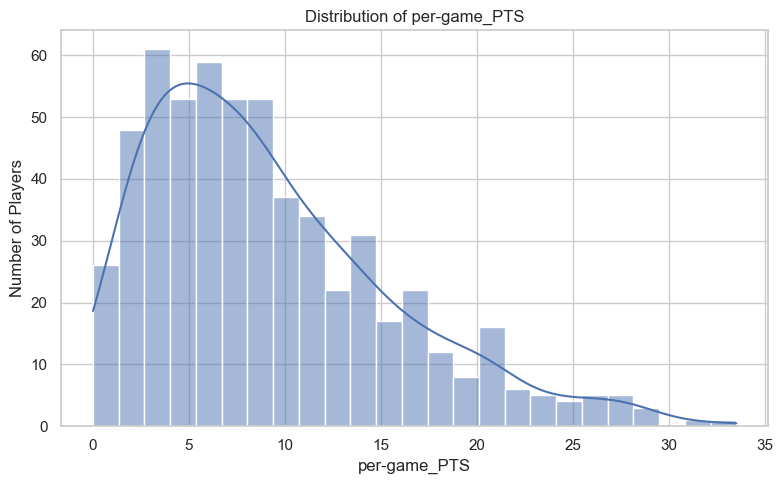

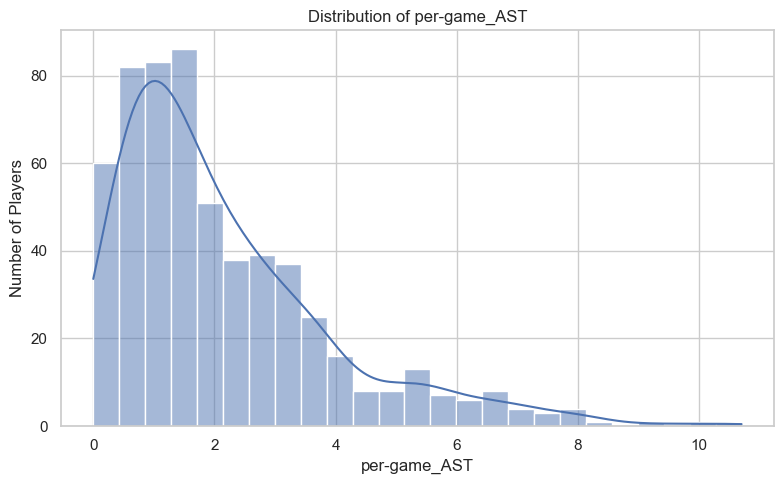

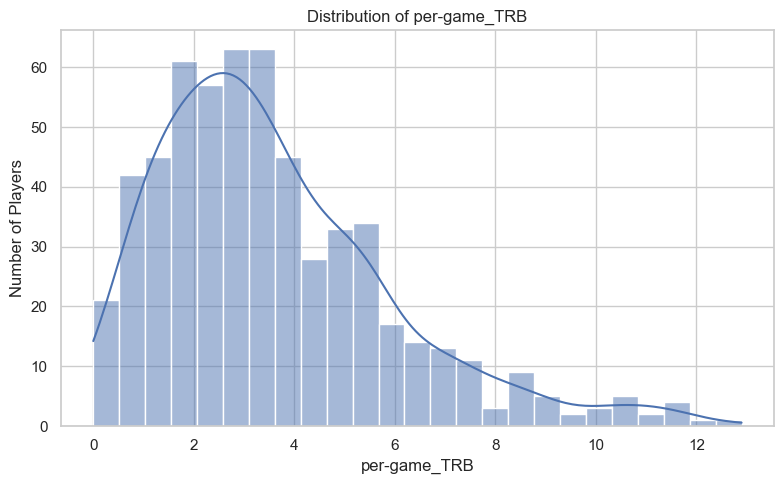

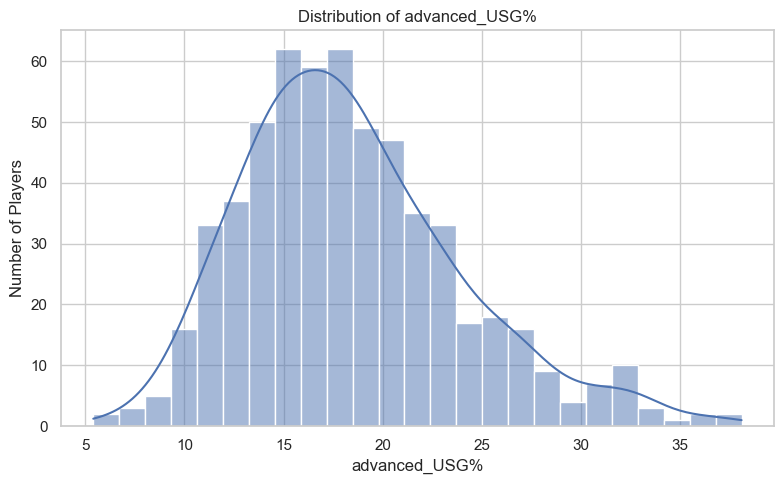

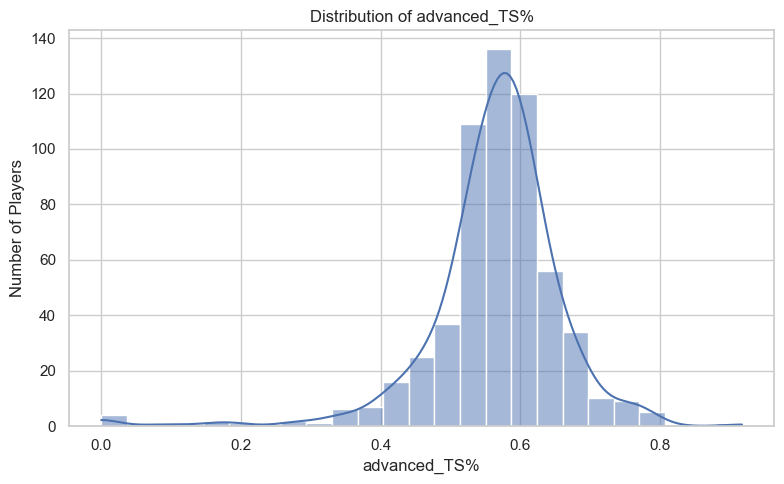

In [29]:

# Create histograms for important player statistics
for col in features:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=col,
        bins=25,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Players")
    plt.tight_layout()
    plt.show()


### Distribution Findings

The distributions of points, assists, and rebounds per game are all right-skewed, meaning that most players produce relatively moderate statistics while a smaller group records much higher numbers. This is especially noticeable in scoring, where relatively few players average more than 20 points per game. Assist distributions also show that only a smaller group of players takes on a major playmaking role. Rebounding follows a similar pattern, with most players averaging fewer than five rebounds per game. In comparison, usage percentage has a more bell-shaped distribution, with most players concentrated around the middle of the range. These patterns demonstrate that NBA players contribute differently across scoring, playmaking, rebounding, and offensive involvement, supporting the need for a statistical approach to identifying player archetypes.

## 5. Correlation Analysis

Correlation analysis is used to examine relationships between different NBA statistics. By identifying which features are strongly or weakly related, we can better understand how different aspects of player performance connect. This analysis can also help identify overlapping features before applying PCA and clustering techniques.

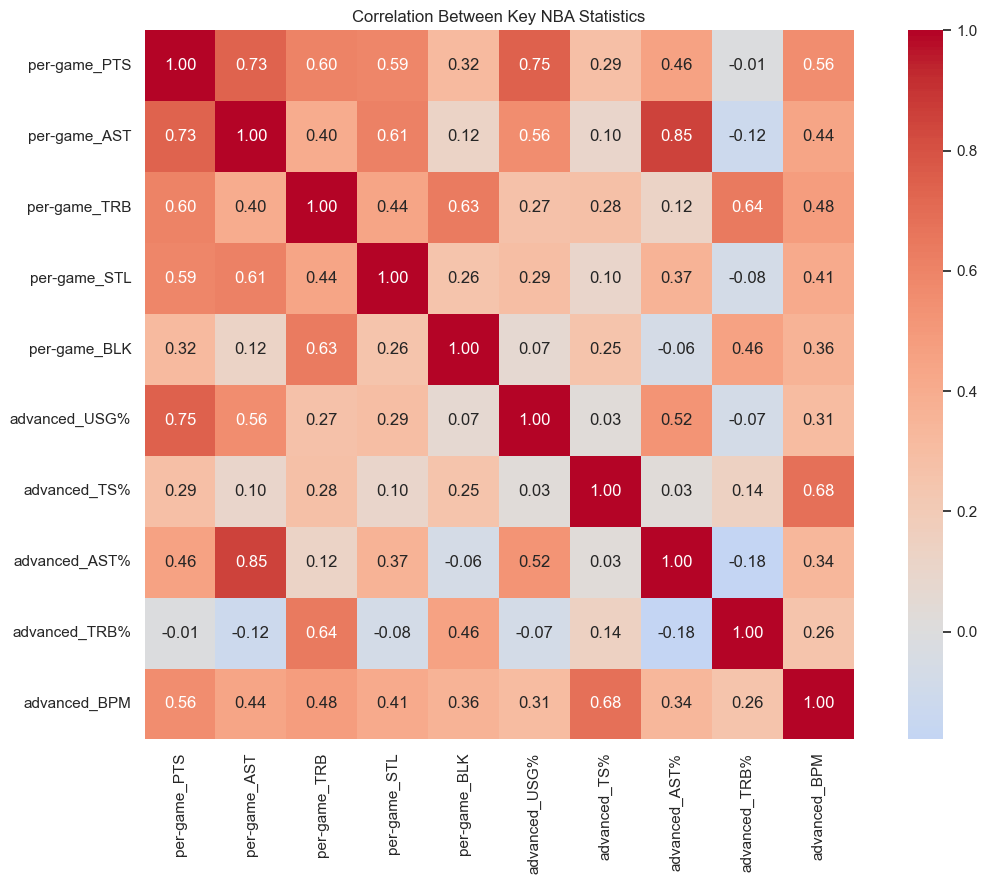

In [30]:

# Select key statistics for correlation analysis
correlation_features = [
    "per-game_PTS",
    "per-game_AST",
    "per-game_TRB",
    "per-game_STL",
    "per-game_BLK",
    "advanced_USG%",
    "advanced_TS%",
    "advanced_AST%",
    "advanced_TRB%",
    "advanced_BPM"
]

# Calculate correlation matrix
corr_matrix = df[correlation_features].corr()

# Plot heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    square=True
)

plt.title("Correlation Between Key NBA Statistics")
plt.tight_layout()
plt.show()


### Correlation Analysis Findings

The correlation heatmap reveals several important relationships between NBA player statistics. The strongest relationship is between assists per game and assist percentage, with a correlation of 0.85, showing that players who record more assists generally have a greater role in creating offense. Points per game also has a strong positive relationship with usage percentage (0.75), suggesting that players with greater offensive involvement tend to score more points. Additionally, true shooting percentage and box plus/minus have a positive correlation of 0.68, indicating a relationship between shooting efficiency and overall player impact. However, some statistics have much weaker relationships, such as usage percentage and true shooting percentage (0.03). These differences show that players can contribute to their teams in different ways rather than being equally strong in every statistical category. This supports our goal of using statistical analysis to identify distinct NBA player archetypes.

## 6. Comparing Player Statistics and Playing Styles

This section compares important NBA statistics to identify differences in player contributions. By examining relationships between scoring and offensive involvement, playmaking and assist percentage, and rebounding and shot-blocking, we can better understand how players develop different roles on the court. These comparisons help provide additional context for the player archetypes developed later in the project.

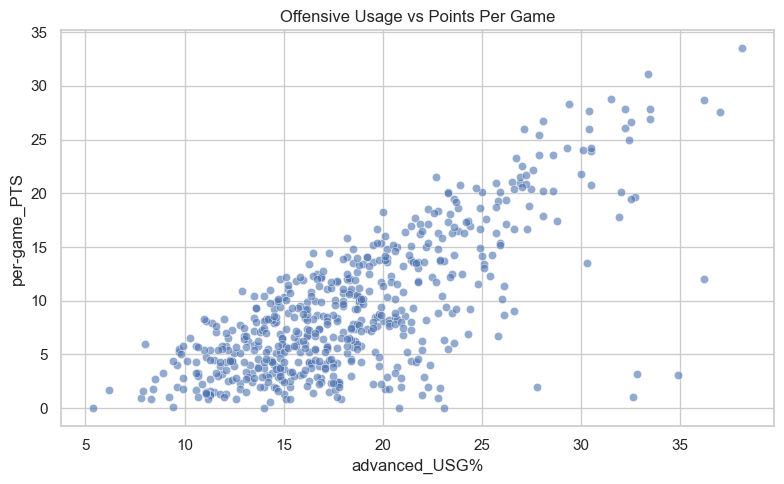

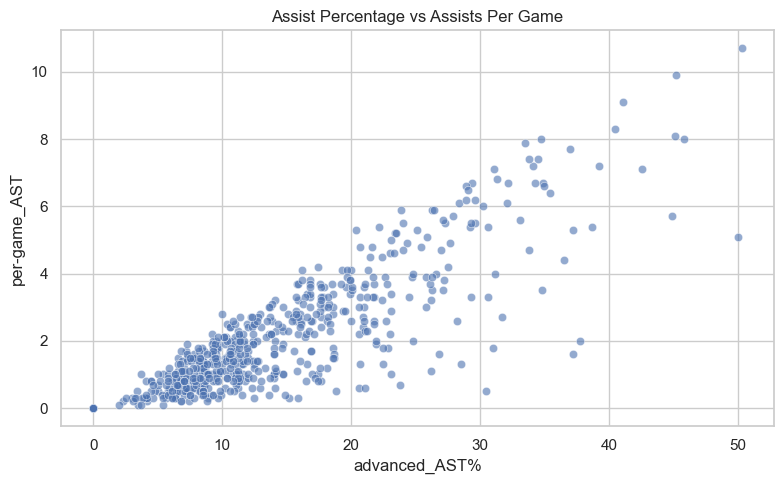

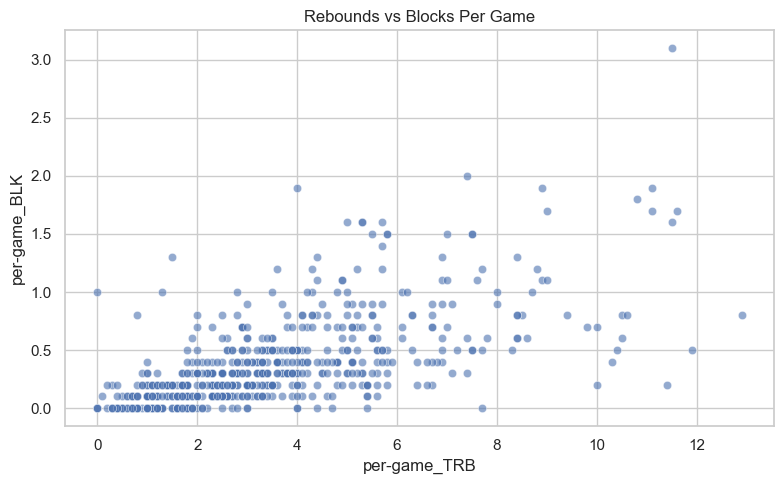

In [31]:

# Compare important player statistics
comparisons = [
    ("advanced_USG%", "per-game_PTS",
     "Offensive Usage vs Points Per Game"),

    ("advanced_AST%", "per-game_AST",
     "Assist Percentage vs Assists Per Game"),

    ("per-game_TRB", "per-game_BLK",
     "Rebounds vs Blocks Per Game")
]

for x, y, title in comparisons:
    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        alpha=0.6
    )

    plt.title(title)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.tight_layout()
    plt.show()


### Player Statistics Comparison Findings

The scatterplots provide additional insight into the relationships between different NBA player statistics. The first comparison shows a strong positive relationship between offensive usage and points per game, suggesting that players who are more involved in their team's offense generally score more points. The second comparison shows an even stronger relationship between assist percentage and assists per game, highlighting the connection between a player's playmaking responsibilities and their actual assist production. The final comparison between rebounds and blocks shows a weaker positive relationship, with much more variation between players. This suggests that although rebounding and shot-blocking can be related, they represent different aspects of player performance. Overall, these comparisons demonstrate that NBA players have different statistical strengths and responsibilities, supporting the use of player archetypes instead of relying entirely on traditional positions.

## 7. EDA Conclusion

Our exploratory data analysis helped us understand the structure of our NBA player dataset and identify important patterns in player performance. We began by examining the dataset, which contained 582 players and 233 features, and found that most missing values were concentrated in award-related columns and certain shooting statistics. We then examined the distributions of important statistics, including points, assists, rebounds, and usage percentage, finding that players have noticeably different levels of production and offensive involvement. Our correlation analysis revealed strong relationships between assists and assist percentage, as well as points and usage percentage. The scatterplots further demonstrated that players contribute in different ways, with some focusing more on scoring, others on playmaking, and others on rebounding and defensive contributions. These findings support our project's goal of identifying NBA player archetypes through statistical analysis rather than relying only on traditional positions. The results of this EDA will help guide our next steps in dimensionality reduction, clustering, and developing meaningful player archetypes.